In [ ]:
!pip install prophet --quiet
!pip install pmdarima --quiet

import os
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

plt.rcParams['figure.figsize'] = (12, 5)
sns.set_style("whitegrid")

print("Upload the annual temperature CSV (e.g. annual_temperature_1901_2017.csv)")
uploaded = files.upload()
print("Now upload the annual rainfall CSV (e.g. annual_rainfall_1901_2017.csv)")
uploaded2 = files.upload()

uploaded_files = list(uploaded.keys()) + list(uploaded2.keys())
print("Uploaded files:", uploaded_files)


Upload the annual temperature CSV (e.g. annual_temperature_1901_2017.csv)


Saving rainfall_area-wt_India_1901-2015.csv to rainfall_area-wt_India_1901-2015 (1).csv
Now upload the annual rainfall CSV (e.g. annual_rainfall_1901_2017.csv)


Saving temperatures.csv to temperatures (1).csv
Uploaded files: ['rainfall_area-wt_India_1901-2015 (1).csv', 'temperatures (1).csv']


In [ ]:
temp_fname = None
rain_fname = None
for f in uploaded_files:
    if 'temp' in f.lower() or 'temperature' in f.lower():
        temp_fname = f
    if 'rain' in f.lower() or 'precip' in f.lower():
        rain_fname = f

if temp_fname is None and len(uploaded_files) >= 1:
    temp_fname = uploaded_files[0]
if rain_fname is None and len(uploaded_files) >= 2:
    rain_fname = uploaded_files[1] if uploaded_files[1] != temp_fname else (uploaded_files[0] if uploaded_files[0] != temp_fname else None)

print("Temperature file:", temp_fname)
print("Rainfall file:", rain_fname)

temp_df = pd.read_csv(temp_fname)
rain_df = pd.read_csv(rain_fname)

print("=== Temperature head ===")
display(temp_df.head())
print("=== Rainfall head ===")
display(rain_df.head())

print("Temperature columns:", temp_df.columns.tolist())
print("Rainfall columns:", rain_df.columns.tolist())


Temperature file: temperatures (1).csv
Rainfall file: rainfall_area-wt_India_1901-2015 (1).csv
=== Temperature head ===


,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JAN-FEB,MAR-MAY,JUN-SEP,OCT-DEC
0,1901,22.40,24.14,29.07,31.91,33.41,33.18,31.21,30.39,30.47,29.97,27.31,24.49,28.96,23.27,31.46,31.27,27.25
1,1902,24.93,26.58,29.77,31.78,33.73,32.91,30.92,30.73,29.80,29.12,26.31,24.04,29.22,25.75,31.76,31.09,26.49
2,1903,23.44,25.03,27.83,31.39,32.91,33.00,31.34,29.98,29.85,29.04,26.08,23.65,28.47,24.24,30.71,30.92,26.26
3,1904,22.50,24.73,28.21,32.02,32.64,32.07,30.36,30.09,30.04,29.20,26.36,23.63,28.49,23.62,30.95,30.66,26.40
4,1905,22.00,22.83,26.68,30.01,33.32,33.25,31.44,30.68,30.12,30.67,27.52,23.82,28.30,22.25,30.00,31.33,26.57


=== Rainfall head ===


,REGION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
0,INDIA,1901,34.7,37.7,18.0,39.3,50.8,113.4,242.2,272.9,124.4,52.7,38.0,8.3,1032.3,72.4,108.1,752.8,99.0
1,INDIA,1902,7.4,4.3,19.0,43.5,48.3,108.8,284.0,199.7,201.5,61.5,27.9,24.4,1030.2,11.7,110.8,794.0,113.8
2,INDIA,1903,17.0,8.3,31.3,17.1,59.5,118.3,297.0,270.4,199.1,117.9,36.9,17.7,1190.5,25.3,107.9,884.8,172.5
3,INDIA,1904,14.4,9.6,31.8,33.1,72.4,164.8,261.0,206.4,129.6,69.0,11.2,16.3,1019.8,24.0,137.4,761.8,96.6
4,INDIA,1905,25.3,20.9,42.7,33.7,55.7,93.3,252.8,200.8,178.4,51.4,9.7,10.5,975.3,46.2,132.2,725.4,71.6


Temperature columns: ['YEAR', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC', 'ANNUAL', 'JAN-FEB', 'MAR-MAY', 'JUN-SEP', 'OCT-DEC']
Rainfall columns: ['REGION', 'YEAR', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC', 'ANNUAL', 'Jan-Feb', 'Mar-May', 'Jun-Sep', 'Oct-Dec']


In [ ]:
def normalize_df(df, value_aliases, kind):
    df = df.copy()
    cols_lc = {c.lower(): c for c in df.columns}
    year_col = None
    for candidate in ['year', 'yyyy', 'yr']:
        if candidate in cols_lc:
            year_col = cols_lc[candidate]; break
    state_col = None
    for candidate in ['state', 'region', 'station', 'area']:
        if candidate in cols_lc:
            state_col = cols_lc[candidate]; break
    val_col = None
    for a in value_aliases:
        if a.lower() in cols_lc:
            val_col = cols_lc[a.lower()]
            break
    if val_col is None:
        numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
        numeric_cols = [c for c in numeric_cols if c != year_col]
        if numeric_cols:
            val_col = numeric_cols[0]
    if val_col is None or year_col is None:
        raise ValueError(f"Could not find Year or value column in {kind} dataset. Found columns: {df.columns.tolist()}")
    df_std = df[[year_col] + ([state_col] if state_col is not None else []) + [val_col]].copy()
    df_std.columns = ['Year'] + (['State'] if state_col is not None else []) + [f'{kind.capitalize()}']
    df_std['Year'] = df_std['Year'].astype(int)
    return df_std

temp = normalize_df(temp_df, value_aliases=['Temperature','AvgTemp','MeanTemp','AnnualTemp','T','Temp'], kind='temp')
rain = normalize_df(rain_df, value_aliases=['Rainfall','Precipitation','Precip','Rain','AnnualRainfall','P'], kind='rain')

print("Temp sample:")
display(temp.head())
print("Rain sample:")
display(rain.head())


Temp sample:


,Year,Temp
0,1901,22.40
1,1902,24.93
2,1903,23.44
3,1904,22.50
4,1905,22.00


Rain sample:


,Year,State,Rain
0,1901,INDIA,34.7
1,1902,INDIA,7.4
2,1903,INDIA,17.0
3,1904,INDIA,14.4
4,1905,INDIA,25.3


In [ ]:
def is_state_level(df):
    return 'State' in df.columns

print("Temp is state level?", is_state_level(temp))
print("Rain is state level?", is_state_level(rain))

if is_state_level(temp) and is_state_level(rain):
    df = pd.merge(temp, rain, on=['Year','State'], how='outer')
else:

    temp_n = temp.copy()
    rain_n = rain.copy()
    temp_n['State'] = np.nan
    rain_n['State'] = np.nan
    df = pd.merge(temp_n, rain_n, on=['Year','State'], how='outer')

if is_state_level(temp):
    national_temp = temp.groupby('Year').agg(Temperature=('Temp','mean')).reset_index()
else:
    national_temp = temp.groupby('Year').agg(Temperature=(temp.columns[-1],'mean')).reset_index()

if is_state_level(rain):
    national_rain = rain.groupby('Year').agg(Rainfall=('Rain','sum' if 'sum' in rain.columns else 'mean')).reset_index()
else:
    national_rain = rain.groupby('Year').agg(Rainfall=(rain.columns[-1],'mean')).reset_index()

if 'Temperature' not in national_temp.columns:
    national_temp.columns = ['Year','Temperature']
if 'Rainfall' not in national_rain.columns:
    national_rain.columns = ['Year','Rainfall']

national = pd.merge(national_temp, national_rain, on='Year', how='outer').sort_values('Year').reset_index(drop=True)

print("National sample:")
display(national.head())


Temp is state level? False
Rain is state level? True
National sample:


,Year,Temperature,Rainfall
0,1901,22.40,34.7
1,1902,24.93,7.4
2,1903,23.44,17.0
3,1904,22.50,14.4
4,1905,22.00,25.3


In [ ]:
years_expected = list(range(1901, 2018))
missing_years = sorted(set(years_expected) - set(national['Year'].tolist()))
print("Missing years in national data (expected 1901-2017):", missing_years)

national = national.set_index('Year').reindex(years_expected).sort_index()
national['Temperature'] = national['Temperature'].interpolate(method='linear').ffill().bfill()
national['Rainfall'] = national['Rainfall'].interpolate(method='linear').ffill().bfill()
national = national.reset_index().rename(columns={'index':'Year'})

from scipy.stats import zscore
for col in ['Temperature','Rainfall']:
    z = zscore(national[col].fillna(method='ffill'))
    z = np.nan_to_num(z)
    outliers = np.where(np.abs(z) > 3)[0]
    print(f"{col} outliers count:", len(outliers))
    lower = national[col].quantile(0.01)
    upper = national[col].quantile(0.99)
    national[col] = national[col].clip(lower, upper)

display(national.tail())


Missing years in national data (expected 1901-2017): []
Temperature outliers count: 2
Rainfall outliers count: 2


/tmp/ipython-input-1131469850.py:16: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  z = zscore(national[col].fillna(method='ffill'))
/tmp/ipython-input-1131469850.py:16: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  z = zscore(national[col].fillna(method='ffill'))


,Year,Temperature,Rainfall
112,2013,24.5600,10.0
113,2014,23.8300,17.3
114,2015,24.5800,17.4
115,2016,26.3236,17.4
116,2017,26.3236,17.4


In [ ]:
import pandas as pd
import numpy as np

print("📘 BASIC STATISTICS SUMMARY:\n")
print(national[['Temperature', 'Rainfall']].describe(), "\n")

corr = national[['Temperature', 'Rainfall']].corr().iloc[0, 1]
print(f"🌦️ Correlation between Temperature and Rainfall: {corr:.2f}")
if corr > 0:
    print("→ Positive correlation: higher temperature generally coincides with higher rainfall.\n")
elif corr < 0:
    print("→ Negative correlation: higher temperature generally coincides with lower rainfall.\n")
else:
    print("→ Little or no correlation between temperature and rainfall.\n")

temp_change = national.Temperature.iloc[-1] - national.Temperature.iloc[0]
print(f"🔥 Temperature change (1901–2017): {temp_change:.2f} °C")

if temp_change > 0:
    print("→ Clear warming trend observed across the years.\n")
else:
    print("→ Cooling or no significant temperature change observed.\n")

rain_change = national.Rainfall.iloc[-1] - national.Rainfall.iloc[0]
print(f"💧 Rainfall change (1901–2017): {rain_change:.2f} mm")

if rain_change > 0:
    print("→ Overall rainfall increase over time.\n")
else:
    print("→ Rainfall decline or fluctuation detected.\n")

national['Decade'] = (national['Year'] // 10) * 10
decadal_summary = national.groupby('Decade')[['Temperature', 'Rainfall']].mean().reset_index()

hottest_decade = decadal_summary.loc[decadal_summary['Temperature'].idxmax()]
coldest_decade = decadal_summary.loc[decadal_summary['Temperature'].idxmin()]
wettest_decade = decadal_summary.loc[decadal_summary['Rainfall'].idxmax()]
driest_decade = decadal_summary.loc[decadal_summary['Rainfall'].idxmin()]

print("📈 DECADAL TRENDS:")
print(f"  Hottest Decade: {int(hottest_decade['Decade'])}s (Avg Temp: {hottest_decade['Temperature']:.2f}°C)")
print(f"  Coldest Decade: {int(coldest_decade['Decade'])}s (Avg Temp: {coldest_decade['Temperature']:.2f}°C)")
print(f"  Wettest Decade: {int(wettest_decade['Decade'])}s (Avg Rainfall: {wettest_decade['Rainfall']:.2f}mm)")
print(f"  Driest Decade: {int(driest_decade['Decade'])}s (Avg Rainfall: {driest_decade['Rainfall']:.2f}mm)\n")


📘 BASIC STATISTICS SUMMARY:

       Temperature    Rainfall
count   117.000000  117.000000
mean     23.682202   19.664547
std       0.809732    9.633471
min      22.095200    4.464000
25%      23.100000   13.000000
50%      23.680000   17.400000
75%      24.180000   24.800000
max      26.323600   51.412000 

🌦️ Correlation between Temperature and Rainfall: -0.36
→ Negative correlation: higher temperature generally coincides with lower rainfall.

🔥 Temperature change (1901–2017): 3.92 °C
→ Clear warming trend observed across the years.

💧 Rainfall change (1901–2017): -17.30 mm
→ Rainfall decline or fluctuation detected.

📈 DECADAL TRENDS:
  Hottest Decade: 2010s (Avg Temp: 24.79°C)
  Coldest Decade: 1920s (Avg Temp: 23.12°C)
  Wettest Decade: 1950s (Avg Rainfall: 25.78mm)
  Driest Decade: 1960s (Avg Rainfall: 15.00mm)



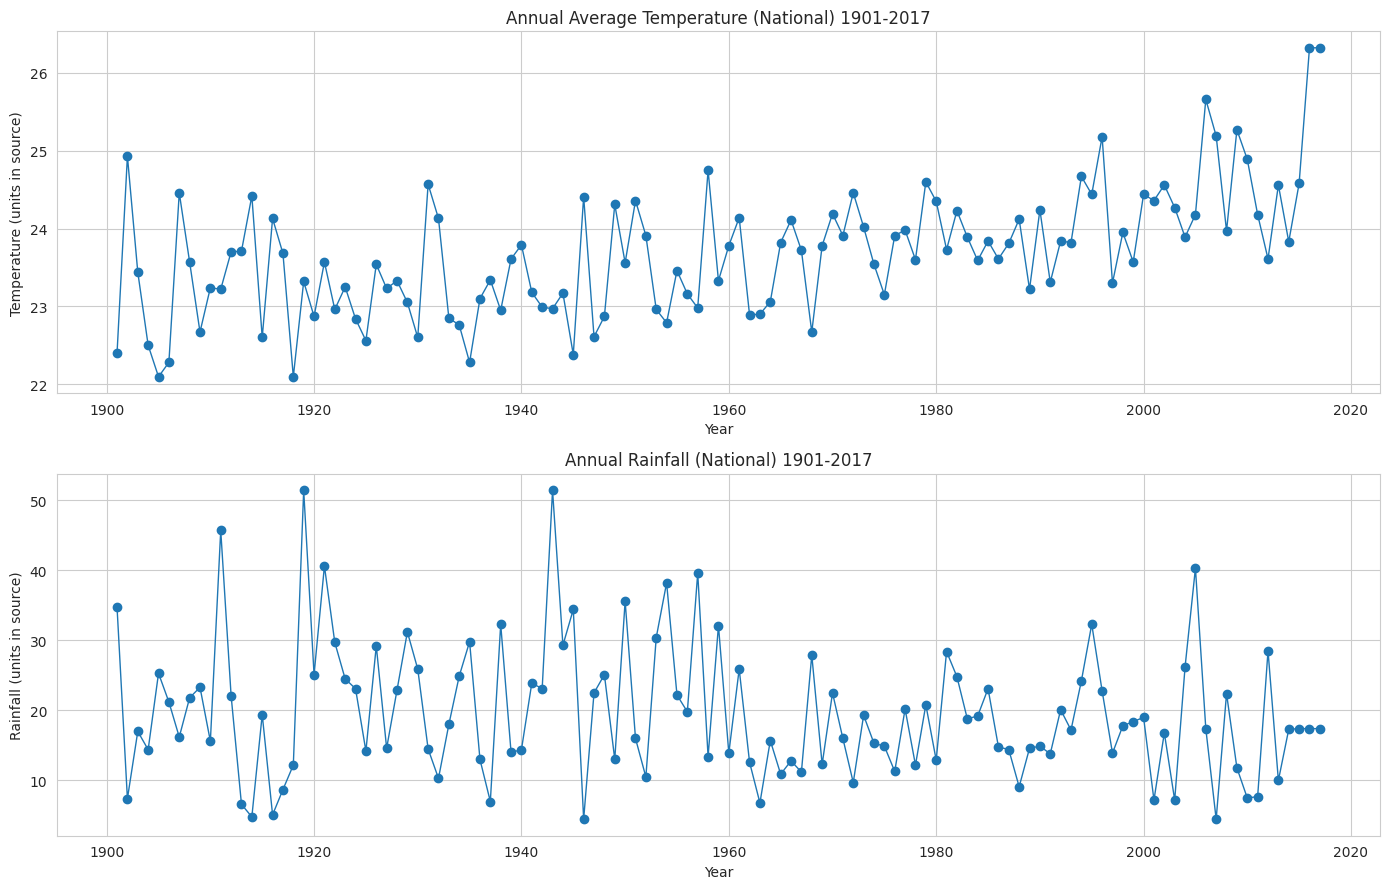

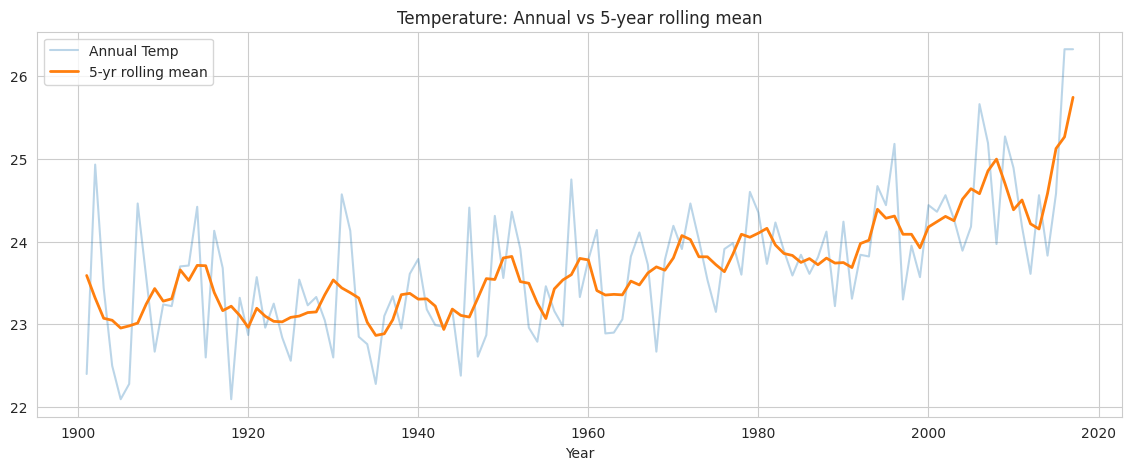

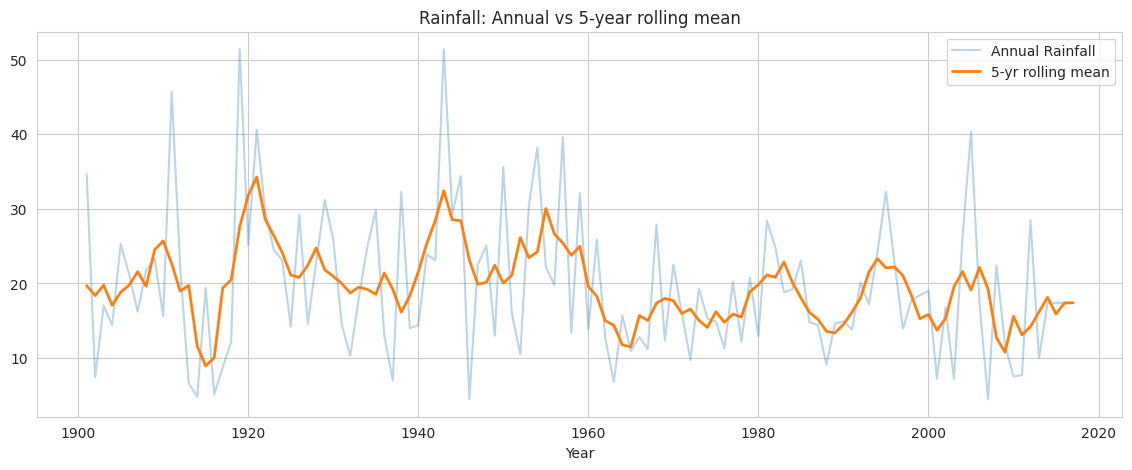

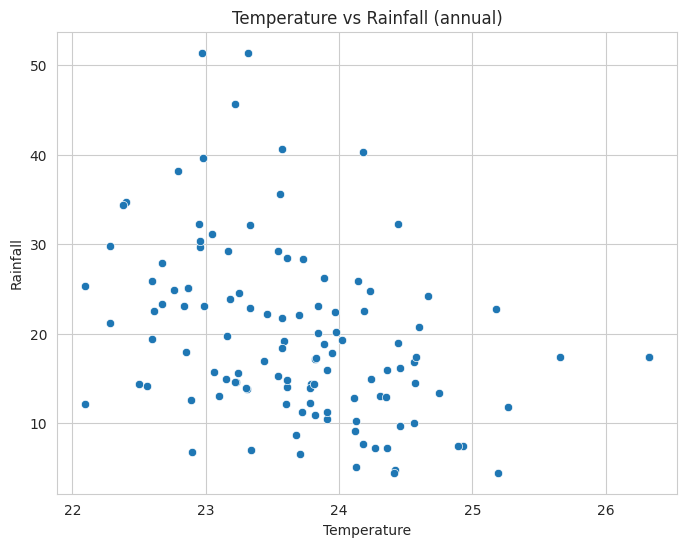

Pearson corr: -0.3639449649517791


In [ ]:
fig, ax = plt.subplots(2,1, figsize=(14,9))
ax[0].plot(national['Year'], national['Temperature'], marker='o', linewidth=1)
ax[0].set_title('Annual Average Temperature (National) 1901-2017')
ax[0].set_xlabel('Year'); ax[0].set_ylabel('Temperature (units in source)')

ax[1].plot(national['Year'], national['Rainfall'], marker='o', linewidth=1)
ax[1].set_title('Annual Rainfall (National) 1901-2017')
ax[1].set_xlabel('Year'); ax[1].set_ylabel('Rainfall (units in source)')
plt.tight_layout()
plt.show()

national['Temp_5yr'] = national['Temperature'].rolling(window=5, center=True, min_periods=1).mean()
national['Rain_5yr'] = national['Rainfall'].rolling(window=5, center=True, min_periods=1).mean()

plt.figure(figsize=(14,5))
plt.plot(national['Year'], national['Temperature'], alpha=0.3, label='Annual Temp')
plt.plot(national['Year'], national['Temp_5yr'], label='5-yr rolling mean', linewidth=2)
plt.title('Temperature: Annual vs 5-year rolling mean')
plt.legend(); plt.xlabel('Year'); plt.show()

plt.figure(figsize=(14,5))
plt.plot(national['Year'], national['Rainfall'], alpha=0.3, label='Annual Rainfall')
plt.plot(national['Year'], national['Rain_5yr'], label='5-yr rolling mean', linewidth=2)
plt.title('Rainfall: Annual vs 5-year rolling mean')
plt.legend(); plt.xlabel('Year'); plt.show()

plt.figure(figsize=(8,6))
sns.scatterplot(x=national['Temperature'], y=national['Rainfall'])
plt.title('Temperature vs Rainfall (annual)')
plt.xlabel('Temperature'); plt.ylabel('Rainfall')
plt.show()

print("Pearson corr:", national[['Temperature','Rainfall']].corr().iloc[0,1])


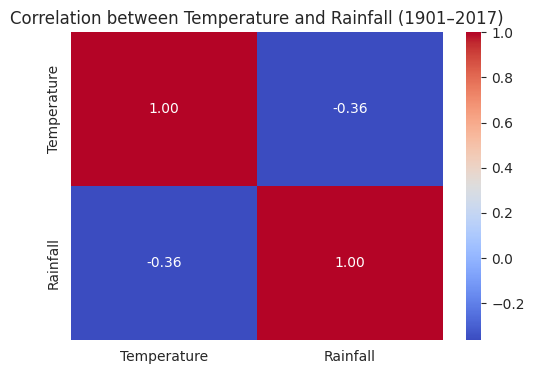

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
sns.heatmap(
    national[['Temperature', 'Rainfall']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title("Correlation between Temperature and Rainfall (1901–2017)")
plt.show()


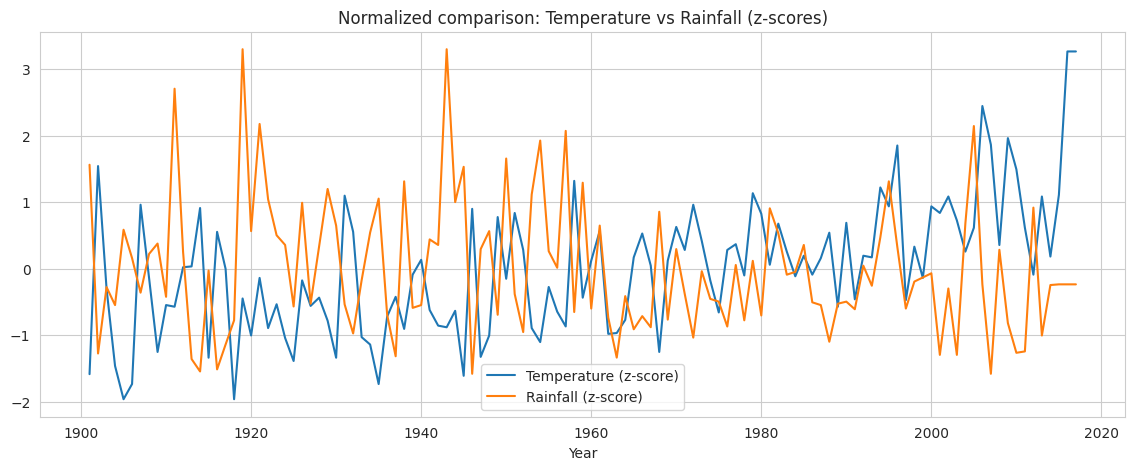

In [ ]:
df_plot = national.copy()
df_plot['Temp_norm'] = (df_plot['Temperature'] - df_plot['Temperature'].mean()) / df_plot['Temperature'].std()
df_plot['Rain_norm'] = (df_plot['Rainfall'] - df_plot['Rainfall'].mean()) / df_plot['Rainfall'].std()

plt.figure(figsize=(14,5))
plt.plot(df_plot['Year'], df_plot['Temp_norm'], label='Temperature (z-score)')
plt.plot(df_plot['Year'], df_plot['Rain_norm'], label='Rainfall (z-score)')
plt.title('Normalized comparison: Temperature vs Rainfall (z-scores)')
plt.legend(); plt.xlabel('Year'); plt.show()


In [ ]:
from sklearn.linear_model import LinearRegression
X_train = national['Year'].values.reshape(-1, 1)
y_temp_train = national['Temperature'].values
y_rain_train = national['Rainfall'].values

future_years = np.arange(2018, 2031).reshape(-1, 1)

model_temp_lr = LinearRegression()
model_temp_lr.fit(X_train, y_temp_train)

temp_forecast_lr = model_temp_lr.predict(future_years)


model_rain_lr = LinearRegression()
model_rain_lr.fit(X_train, y_rain_train)

rain_forecast_lr = model_rain_lr.predict(future_years)

forecast_df_lr = pd.DataFrame({
    'Year': future_years.flatten(),
    'Temperature_LR_Forecast': temp_forecast_lr,
    'Rainfall_LR_Forecast': rain_forecast_lr
})

print("Linear Regression Forecasts (2018-2030):")
display(forecast_df_lr.head())
display(forecast_df_lr.tail())

Linear Regression Forecasts (2018-2030):


,Year,Temperature_LR_Forecast,Rainfall_LR_Forecast
0,2018,24.495977,16.526867
1,2019,24.509770,16.473686
2,2020,24.523563,16.420505
3,2021,24.537356,16.367324
4,2022,24.551148,16.314143


,Year,Temperature_LR_Forecast,Rainfall_LR_Forecast
8,2026,24.606320,16.101419
9,2027,24.620112,16.048238
10,2028,24.633905,15.995057
11,2029,24.647698,15.941876
12,2030,24.661491,15.888695


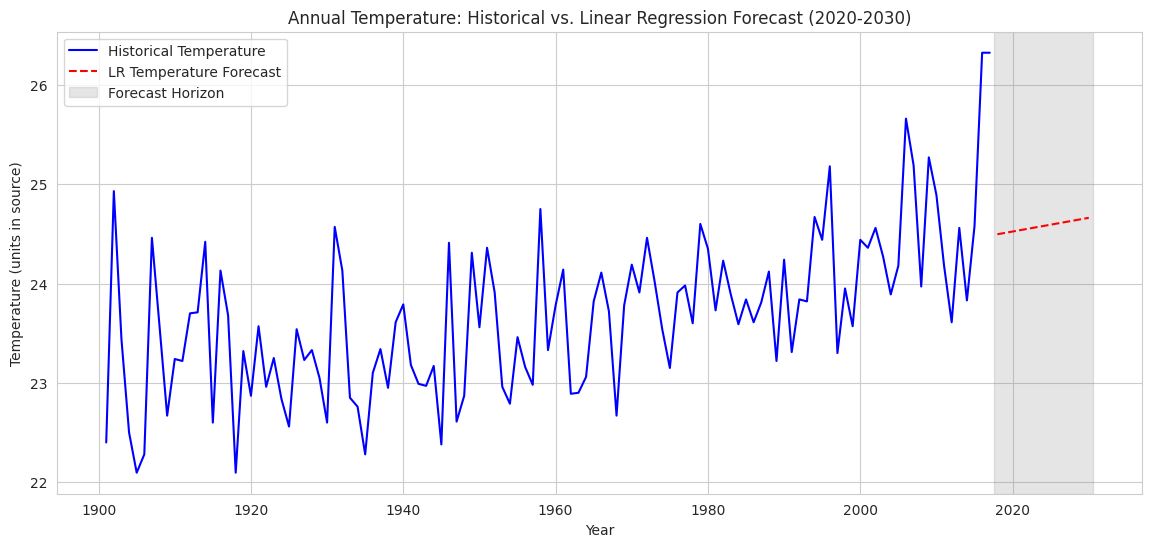

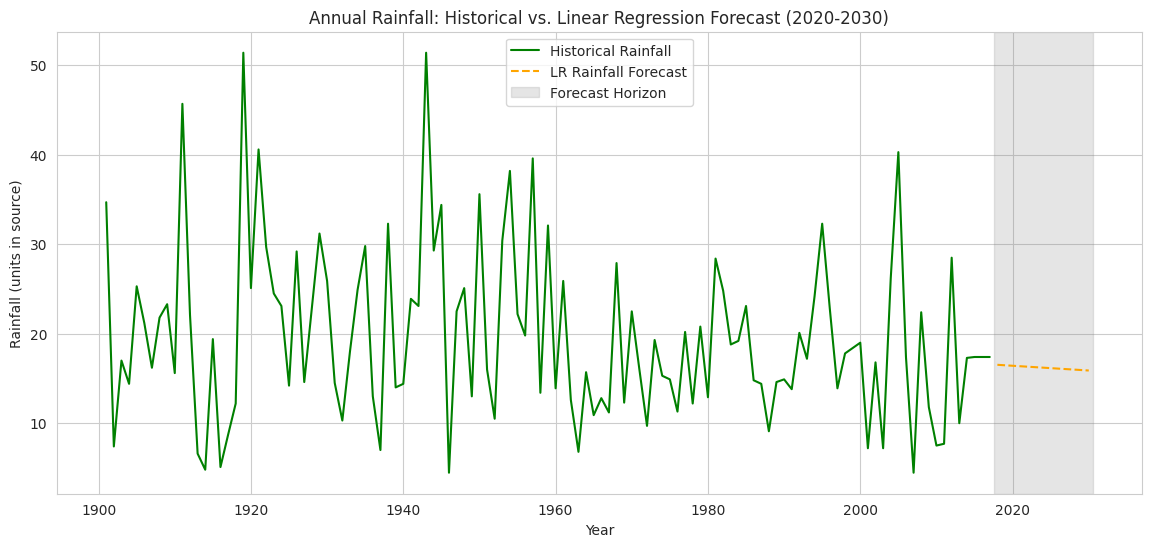

In [ ]:
plt.figure(figsize=(14, 6))
plt.plot(national['Year'], national['Temperature'], label='Historical Temperature', color='blue')
plt.plot(forecast_df_lr['Year'], forecast_df_lr['Temperature_LR_Forecast'], label='LR Temperature Forecast', color='red', linestyle='--')
plt.title('Annual Temperature: Historical vs. Linear Regression Forecast (2020-2030)')
plt.xlabel('Year')
plt.ylabel('Temperature (units in source)')
plt.axvspan(2017.5, 2030.5, color='gray', alpha=0.2, label='Forecast Horizon')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(14, 6))
plt.plot(national['Year'], national['Rainfall'], label='Historical Rainfall', color='green')
plt.plot(forecast_df_lr['Year'], forecast_df_lr['Rainfall_LR_Forecast'], label='LR Rainfall Forecast', color='orange', linestyle='--')
plt.title('Annual Rainfall: Historical vs. Linear Regression Forecast (2020-2030)')
plt.xlabel('Year')
plt.ylabel('Rainfall (units in source)')
plt.axvspan(2017.5, 2030.5, color='gray', alpha=0.2, label='Forecast Horizon')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from google.colab import files

cleaned_fname = 'cleaned_national_climate_1901_2017_for_tableau.csv'

import pandas as pd
national.to_csv(cleaned_fname, index=False)

files.download(cleaned_fname)

print("✅ Cleaned dataset saved and download started:", cleaned_fname)



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Cleaned dataset saved and download started: cleaned_national_climate_1901_2017_for_tableau.csv
